# MNIST anomaly detection - autoencoder

Study preparation. Run all cells from top to bottom. Outputs below are from a fresh Python execution, not the supplied saved outputs. Full original epoch counts and datasets are preserved. Numeric results can vary across software versions.

## Cell 1: Set up reproducibility

Use deterministic seeds and CPU execution settings. Exact floating-point results can still vary.

In [1]:
# Reproducible CPU-friendly setup. Colab already includes the main libraries.
import os, random
os.environ["TF_NUM_INTRAOP_THREADS"] = "2"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
import numpy as np
import tensorflow as tf
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("Execution device: CPU")


TensorFlow: 2.16.1
Execution device: CPU

## Cell 2: Import autoencoder tools

The functional Keras API connects an input to encoder and decoder Dense layers. NumPy computes reconstruction errors; Matplotlib displays the results.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

## Cell 3: Load MNIST

Load the standard training and test splits. Labels are used to choose normal and anomalous digits, not as reconstruction targets.

In [3]:
# 1. Load Dataset
# ------------------------------------------------
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)

## Cell 4: Normalize and flatten

Convert pixels to float32 in [0,1], then reshape each 28 x 28 image into 784 values.

In [4]:
# 2. Normalize Data
# ------------------------------------------------
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
# Convert 28x28 images to 784-dimensional vectors
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

## Cell 5: Select normal training samples

Digit 0 defines normality in this demonstration. Train only on the 5923 training zeros, so the network learns to reconstruct normal patterns.

In [5]:
# 3. Select Normal Training Data
# Digit 0 = Normal
# ------------------------------------------------
normal_train = x_train[y_train == 0]
print("Normal training samples:", normal_train.shape)

Normal training samples: (5923, 784)

## Cell 6: Choose evaluation samples

Keep test digits 0 and 1 only. A zero is normal and a one is an anomaly by this artificial task definition, not because digit 1 is intrinsically anomalous.

In [6]:
# 4. Select Test Data
# Digit 0 = Normal
# Digit 1 = Anomaly
# ------------------------------------------------
test_mask = (y_test == 0) | (y_test == 1)
x_test_anomaly = x_test[test_mask]
y_test_anomaly = y_test[test_mask]

## Cell 7: Build the encoder

Input has 784 features. Dense layers reduce it to 128 and then a 64-dimensional latent representation. ReLU allows nonlinear feature learning.

In [7]:
# 5. Encoder
# ------------------------------------------------
input_layer = Input(shape=(784,))
encoded = Dense(128, activation="relu")(input_layer)
encoded = Dense(64, activation="relu")(encoded)

## Cell 8: Build the decoder

Expand the latent vector back to 128 and then 784 outputs. Sigmoid keeps reconstructed pixel values in [0,1].

In [8]:
# 6. Decoder
# ------------------------------------------------
decoded = Dense(128, activation="relu")(encoded)
decoded = Dense(784, activation="sigmoid")(decoded)

## Cell 9: Connect the autoencoder

A functional Model maps original input pixels to reconstructed pixels through encoder and decoder.

In [9]:
# 7. Create Autoencoder
# ------------------------------------------------
autoencoder = Model(input_layer, decoded)

## Cell 10: Compile

Adam updates weights; mean squared error is the average squared reconstruction error. MAE is reported as an additional metric. The complete model has 218,192 trainable parameters.

In [10]:
# 8. Compile Model
# ------------------------------------------------
autoencoder.compile(
 optimizer="adam",
 loss="mse",
 metrics=["mae"]
)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,192 (852.31 KB)

 Trainable params: 218,192 (852.31 KB)

 Non-trainable params: 0 (0.00 B)

## Cell 11: Train to reconstruct zeros

Input and target are both normal_train. Train for 20 epochs, batch size 256. validation_split=0.2 holds out part of the normal training samples.

In [11]:
# 9. Train Model
# ------------------------------------------------
history = autoencoder.fit(
 normal_train,
 normal_train,
 epochs=20,
 batch_size=256,
 validation_split=0.2,
 shuffle=True
)

Epoch 1/20
 1/19 ━━━━━━━━━━━━━━━━━━━━ 12s 691ms/step - loss: 0.2286 - mae: 0.468011/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2176 - mae: 0.4554   19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1563 - mae: 0.3500 - val_loss: 0.0696 - val_mae: 0.1420
Epoch 2/20
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0702 - mae: 0.141911/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0680 - mae: 0.1361 19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0625 - mae: 0.1288 - val_loss: 0.0538 - val_mae: 0.1162
Epoch 3/20
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0533 - mae: 0.115512/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0531 - mae: 0.1146 19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0500 - mae: 0.1104 - val_loss: 0.0442 - val_mae: 0.1017
Epoch 4/20
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0432 - mae: 0.100412/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0442 - mae: 0.1009 19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0428 - mae: 0.0982 - val_loss: 0.0396 - val

## Cell 12: Reconstruct evaluation images

Run the mixed test zeros and ones through the autoencoder. The output has the same 784-dimensional shape as the input.

In [12]:
# 10. Reconstruct Test Data
# ------------------------------------------------
reconstructed = autoencoder.predict(x_test_anomaly)

 1/67 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 966us/step67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

## Cell 13: Calculate anomaly scores

For each sample average the squared pixel difference along axis=1. A larger reconstruction error means the sample looks less like the training zeros.

In [13]:
# 11. Calculate Reconstruction Error
# ------------------------------------------------
reconstruction_error = np.mean(
 np.square(x_test_anomaly - reconstructed),
 axis=1
)

## Cell 14: Set the threshold

Preserved original method: calculate the 95th percentile of reconstruction errors of test-set zeros. Roughly 5% of these normal calibration samples will exceed it. This uses the test set to calibrate the threshold, so the results are NOT an unbiased independent test. In a real evaluation, calibrate on a separate normal validation set.

In [14]:
# 12. Calculate Threshold Using Normal Data
# ------------------------------------------------
normal_test = x_test[y_test == 0]
normal_reconstructed = autoencoder.predict(normal_test)
normal_error = np.mean(
 np.square(normal_test - normal_reconstructed),
 axis=1
)
threshold = np.percentile(normal_error, 95)
print("Anomaly Threshold:", threshold)

 1/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Anomaly Threshold: 0.028205265849828718

## Cell 15: Flag anomalies

Compare each reconstruction error to the threshold. True means anomaly. Print the first 20 decisions; these are model decisions, not a guaranteed ground-truth match.

In [15]:
# 13. Detect Anomalies
# ------------------------------------------------
predictions = reconstruction_error > threshold
print("\nFirst 20 Predictions:")
for i in range(20):
 if predictions[i]:
      print(i, "-> Anomaly")
 else:
      print(i, "-> Normal")


First 20 Predictions:
0 -> Anomaly
1 -> Normal
2 -> Anomaly
3 -> Normal
4 -> Normal
5 -> Anomaly
6 -> Normal
7 -> Normal
8 -> Anomaly
9 -> Anomaly
10 -> Anomaly
11 -> Anomaly
12 -> Anomaly
13 -> Anomaly
14 -> Normal
15 -> Anomaly
16 -> Normal
17 -> Normal
18 -> Anomaly
19 -> Anomaly

## Cell 16: Compare image and reconstruction

Show the first selected evaluation image and its reconstructed version side by side. A poor reconstruction can yield a larger anomaly score.

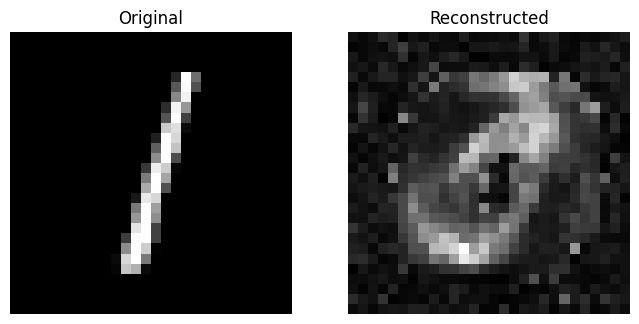

In [16]:
# 14. Display Original and Reconstructed Image
# ------------------------------------------------
index = 0
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(
 x_test_anomaly[index].reshape(28, 28),
 cmap="gray"
)
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(
 reconstructed[index].reshape(28, 28),
 cmap="gray"
)
plt.title("Reconstructed")
plt.axis("off")
plt.show()

## Cell 17: Plot error distributions

Histogram the reconstruction scores for real zeros and ones separately. The dashed line is the threshold. Overlap shows that a threshold can make both false positives and false negatives.

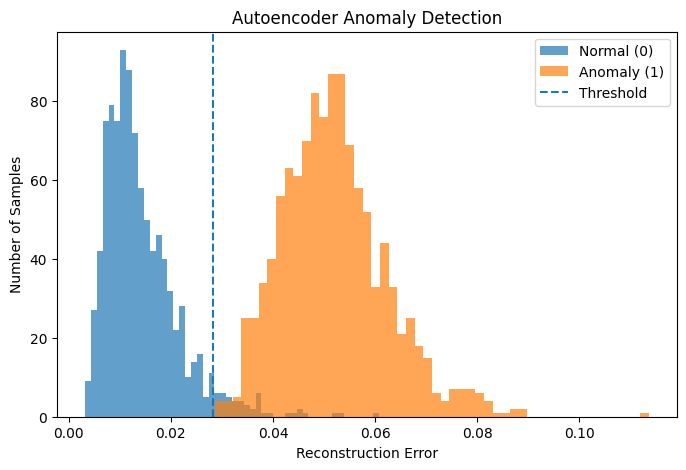

In [17]:
# 15. Plot Reconstruction Error
# ------------------------------------------------
plt.figure(figsize=(8, 5))
plt.hist(
 reconstruction_error[y_test_anomaly == 0],
 bins=50,
 alpha=0.7,
 label="Normal (0)"
)
plt.hist(
 reconstruction_error[y_test_anomaly == 1],
 bins=50,
 alpha=0.7,
 label="Anomaly (1)"
)
plt.axvline(
 threshold,
 linestyle="--",
 label="Threshold"
)
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Samples")
plt.title("Autoencoder Anomaly Detection")
plt.legend()
plt.show()